In [ ]:
'''objetivos:
comparar resposta ao ruído para FF de 0.1 a 40% usando os métodos:
dixon
multieco 3 pontos
multi-interferência 7 pontos
ann

materiais e métodos
datasets de teste:
FF: 1% a 40%, step de 1% (40 steps), randomizado uniforme, 10 iterações por step
T2* 0.9, 1.3, 2.1 ppm randomizados na gaussiana limitados entre 0 e 1
T2* 4.2 e 5.3 ppm fixos
T2* 4.7 (agua) ppm randomizado na gaussiana limitado entre 0 e 1
ruído randomizado adicionado em relação ao primeiro ponto:
teste com SNR = 200
teste com SNR = 100
teste com SNR = 50
teste com SNR = 25

dataset de treino do ann:
dataset padrão
FF: 1% a 100%, step de 0.1% (1000 steps), linear, 50 iterações por step
T2* 0.9, 1.3, 2.1 ppm randomizados na gaussiana limitados entre 0 e 1
T2* 4.2 e 5.3 ppm fixos
T2* 4.7 (agua) ppm randomizado na gaussiana limitado entre 0 e 1
ruído randomizado uniforme adicionado em relação ao primeiro ponto:
SNR [200 25]

MÉTRICAS
standard deviation of the pairwise difference and correlation coefficient between real and estimation
sensitivity, specificity 
	(threshold 6.25%? 
	two-sided confidence intervals 95%?
	bias-corrected and accelerated intervals from bootstrap distribution of 1000 resampled datasets?
	thresholds 5,6,7,8%?)
regression slopes and intercepts
	null hypostesis: slope 1, intercept 0
	two-tailed t test, alpha=0.05
'''

In [1]:
# bibliotecas e funções para gerar o dataset

# INICIALIZAÇÃO DAS BIBLIOTECAS
import itertools
import pandas
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import statsmodels.formula.api as smf
from scipy.stats import truncnorm
from scipy.optimize import curve_fit
from sklearn.metrics import accuracy_score

#################################### FUNÇÕES PARA OBTENÇÃO DO SINAL ####################################

def get_truncated_normal(mean=0, sd=1, low=0, upp=10):
    return(truncnorm((low - mean) / sd, (upp - mean) / sd, loc=mean, scale=sd))

def set_random_rho(ff):
    '''
    Returns the Proton Density values rho_fat, rho_water for a given Fat fraction ff
    parameters: ff     -> float 0>1 fat fraction
    returns:    rho_fat, rho_water
    '''
    rho_fat = np.random.rand()
    rho_water = (rho_fat/ff)-rho_fat
    return(rho_fat, rho_water)

def discrete_timeseries(n_echoes):
    '''
    This function calculates the echo times for n_echoes in the GRE IP-OP sequence, considering TE = 0.0011515, 
    which corresponds to water (4.7 ppm) and fat (1.3 ppm) interference at 3 Tesla.
    parameters: n_echoes     -> integer >0, number of equally spaced echoes
    returns:    echo_times
     '''
    # TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    return(echo_times)

def gen_GRE_noise(echo_times, rho_fat, rho_water, t2fat09=0.083, t2fat13=0.061, t2fat21=0.052, t2fat275=0.051, 
                  t2fat42=0.0254, t2fat53=0.0387, t2water47=0.027, noise_level=0.00):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton (T2* and characteristic ppm frequency values).
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
                t2star     -> array >0, T2* values for fat peaks at 0.9, 1.3., 2.1, 2.75, 4.2 and 5.3ppm (fat) and 
                                        water at 4.7 ppm. Standard values are [0.030, 0.040, 0.051, 0.052, 0.062, 0.083, 0.023]
                noise_sd   -> float >0, noise level (1/SNR) as proportion of the first signal point intensity 
                                        (default is 0%)
    returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
    # rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    rho = np.array([rho_fat*0.088, rho_fat*0.7, rho_fat*0.12, rho_fat*0.006, rho_fat*0.039, rho_fat*0.047, rho_water])
    
    # individual T2* values
    t2star = np.array([t2fat09, t2fat13, t2fat21, t2fat275, t2fat42, t2fat53, t2water47])
    
    # frequency in parts per million for each moiety
    freq_ppm = np.array([0.9, 1.3, 2.1, 2.75, 4.2, 5.3, 4.7])
    
    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0)      # magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) # Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    # calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
        
    # obtain sum & add noise
    Ssum = (len(echo_times))
    Ssum = np.zeros(Ssum,dtype='complex')
    Ssum = np.sum(S, axis=0)
    
    for t,TE in enumerate(echo_times):
        Ssum[t] = Ssum[t].real+Ssum[0].real*noise_level*np.random.normal()+1j*(Ssum[t].imag+Ssum[0].imag*noise_level*np.random.normal())
 
    # obtain absolute value
    Sabs = (len(echo_times))
    Sabs = np.zeros(Sabs,dtype='complex')
    Sabs = np.absolute(Ssum)
    return(Sabs)

In [2]:
# bibliotecas e funções para métodos de estimação

########################################## MULTI-INTERFERENCIA ##########################################

def fit_multiinterf(echo_times, rho_fat, rho_water, t2star):
    '''
    This function fits the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T.
    It is based on studies by Hamilton (T2* and characteristic ppm frequency values).
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs -> float > 0, absolute signal intensity in arbitrary units (equivalent to ydata)
    '''
    
    echo_times = np.array(echo_times)
    rho_fat = np.array(rho_fat)
    rho_water = np.array(rho_water)
    t2star = np.array(t2star)
    
    # cn is the fractional proton density of each fat moiety (Yokoo) (see freq_ppm)
    cn = np.array([0.12, 0.7, 0.088,]) 
    
    # frequency in parts per million for each fat moiety
    ppm_fat = np.array([2.1, 1.3, 0.9])
    ppm_water = np.array(4.7)
    
    magField = np.array(3.0)       # magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.577e6) # Hydrogen gyromagnetic ratio, Hz/T
    freq_water = np.array(ppm_water*magField*hydroGyro/1e6) # water frequency in Hertz
    
    # relative frequency for each fat to that of water
    freqr_fat = np.zeros(len(ppm_fat))
    for n, fppm in enumerate(ppm_fat):
        freqr_fat[n] = freq_water-(fppm*magField*hydroGyro/1e6)
    
    # calculate the signal for each moiety    
    S = (len(freqr_fat),len(echo_times))
    S = np.zeros(S,dtype='complex')
        # three fat signals
    for n, moieties in enumerate(freqr_fat):
        for t,TE in enumerate(echo_times):
            S[n,t] = cn[n]*np.exp(2.0*np.pi*1j*freqr_fat[n]*TE)
    
    Ssum= len(echo_times)
    Ssum = np.zeros(Ssum)
    Ssum = np.sum(S, axis=0)                     # sum of fat signals
    Sabs = np.absolute(rho_water + rho_fat*Ssum) # multiply rho_fat and add rho_water, take absolute value
    Sfinal = len(echo_times)
    Sfinal = np.zeros(Sfinal)
    for t,TE in enumerate(echo_times):
        Sfinal[t] = Sabs[t]*np.exp(-TE/t2star) # exponential decay
    
    return(Sfinal)

############################################# TRIPLE-ECHOE #############################################

def fit_tripleEcho(echo_times, voxelSignal):
    '''
    this function calculates the fat fraction according to corrected Dixon's method, which considers a single T2* effect.
    parameters: voxelSignal -> array, float >0, signal intensities, at least two values.
    returns:    fat_fraction -> float
    '''
    s1 = voxelSignal[0]
    s2 = voxelSignal[1]
    s4 = voxelSignal[3]
    deltaTE = echo_times[1]-echo_times[0]
    t2star = deltaTE/np.log(s2/s4)
    
    rho_water = (s2 * np.exp(echo_times[1]/t2star) + s1* np.exp(echo_times[0]/t2star))/2
    rho_fat = (s2 * np.exp(echo_times[1]/t2star) - s1* np.exp(echo_times[0]/t2star))/2

    return(rho_fat, rho_water)

############################################### DIXON ###############################################

def fit_dixon(voxelSignal):
    '''
    this function calculates the fat fraction according to Dixon's method.
    parameters: voxelSignal -> array, float >0, signal intensities, at least two values.
    returns:    fat_fraction -> float
    '''
    s1 = voxelSignal[0]
    s2 = voxelSignal[1]
    rho_water = (s2 + s1)/2
    rho_fat = (s2 - s1)/2
    return(rho_fat, rho_water)

############################################## CALC_FATFRAC ##############################################

def calc_fatfrac(fitted_parameters):
    '''
    Returns the Fat Fraction ff  for values rho_fat (fitted_parameters[0]) and rho_water (fitted_parameters[1])
    parameters: fitted parameters -> list or tuple, where rho_fat = fitted_parameters[0] and rho_water fitted_parameters[1])
    returns:    ff - > fat fraction
    '''
    ff =  fitted_parameters[0] / (fitted_parameters[0] + fitted_parameters[1])
    return(ff)

In [3]:
def zona(snr):
    ############################################ SETTINGS ############################################
    total_size = 5000
    ff = np.random.uniform(0.01, 0.4, total_size) # fat fraction, limites, numero de discretizações
    ff_iterations = 1 # numero de iterações do mesmo valor de FF

    ############################################# CÓDIGO #############################################
    ###################################### parâmetros do sinal ######################################
    
                                  # mean, sd, min, max (para não obter valor negativo)
    t2fat09 = get_truncated_normal(0.083, 0.0163, low=0.001, upp=1).rvs(total_size)
    t2fat13 = get_truncated_normal(0.061, 0.0113, low=0.001, upp=1).rvs(total_size)
    t2fat21 = get_truncated_normal(0.052, 0.0298, low=0.001, upp=1).rvs(total_size)
    t2fat275 = np.repeat(0.051,total_size)
    t2fat42 = np.repeat(0.0254,total_size)
    t2fat53 = np.repeat(0.0387,total_size)
    t2water47 = get_truncated_normal(0.027, 0.0066, low=0.001, upp=1).rvs(total_size)

    noise_values = np.repeat(1/snr, total_size) # ruido (1/snr) minimo, maximo, numero de iter

    ######################################## inicialização dos arrays ########################################

    ff_repeat = np.repeat(ff,ff_iterations) # repete ff para preencher a lista

    signal_collection = np.zeros([total_size,7]) # sinal normalizado
    xdata = discrete_timeseries(7)               # gerar TEs para 3T

    ############################################# gera as curvas #############################################
    n=0
    for fat_fraction in ff_repeat:
        rho_fat, rho_water = set_random_rho(fat_fraction) # obter rhos aleatorios que atendam a uma determinada FF
        signal = gen_GRE_noise(xdata, rho_fat, rho_water, t2fat09[n], t2fat13[n], t2fat21[n], 
                               t2fat275[n], t2fat42[n], t2fat53[n], t2water47[n], noise_values[n]) # obter sinal GRE
        signal_collection[n,:] = signal # colocar os sinais numa coleção, pontos 0:6
        n = n+1
    
    res_dixon = []
    res_tripl = []
    res_multi = []
    for ydata in signal_collection:
        p0 = (ydata[0]/2, ydata[1]/3)
        
        # DIXON
        par = fit_dixon(ydata)
        res_dixon.append(calc_fatfrac(par))
        
        # TRIPLE
        par = fit_tripleEcho(xdata, ydata)
        res_tripl.append(calc_fatfrac(par))
        
        # MULTI
        bd = (0, [np.inf,np.inf,1])
        fitted_par, pcov = curve_fit(fit_multiinterf, xdata, ydata, bounds=bd)
        res_multi.append(calc_fatfrac(fitted_par))
    
    return(ff, res_dixon, res_tripl, res_multi)

################################################# ACCURACY #################################################

def accu(ff_real, ff_calc, threshold):
    ff_real_bin = []
    ff_calc_bin = []
    for i in range(len(ff_real)):
        if(ff_real[i] < threshold):
            ff_real_bin.append(0)
        else:
            ff_real_bin.append(1)
    for i in range(len(ff_calc)):
        if(ff_calc[i] < threshold):
            ff_calc_bin.append(0)
        else:
            ff_calc_bin.append(1)
    
    accuracy = accuracy_score(ff_real_bin, ff_calc_bin)
    
    return(accuracy)

In [4]:
## -------------------------------------> SNR = 200 <------------------------------------- ##
snr_200 = 200

ff_200, res_dixon_200, res_tripl_200, res_multi_200 = zona(snr_200)

print('DIXON 0.04: %.f' % accu(ff_200, res_dixon_200, 0.04))
print('DIXON 0.06: %.f' % accu(ff_200, res_dixon_200, 0.06))
print('DIXON 0.08: %.f' % accu(ff_200, res_dixon_200, 0.08))
print('DIXON 0.10: %.f' % accu(ff_200, res_dixon_200, 0.10))
print('DIXON 0.45: %.f' % accu(ff_200, res_dixon_200, 0.45))
print('DIXON 0.50: %.f' % accu(ff_200, res_dixon_200, 0.50))
print('DIXON 0.55: %.f' % accu(ff_200, res_dixon_200, 0.55))
print('')
print('tripl 0.04: %.f' % accu(ff_200, res_tripl_200, 0.04))
print('tripl 0.06: %.f' % accu(ff_200, res_tripl_200, 0.06))
print('tripl 0.08: %.f' % accu(ff_200, res_tripl_200, 0.08))
print('tripl 0.10: %.f' % accu(ff_200, res_tripl_200, 0.10))
print('tripl 0.45: %.f' % accu(ff_200, res_tripl_200, 0.45))
print('tripl 0.50: %.f' % accu(ff_200, res_tripl_200, 0.50))
print('tripl 0.55: %.f' % accu(ff_200, res_tripl_200, 0.55))
print('')
print('multi 0.04: %.f' % accu(ff_200, res_multi_200, 0.04))
print('multi 0.06: %.f' % accu(ff_200, res_multi_200, 0.06))
print('multi 0.08: %.f' % accu(ff_200, res_multi_200, 0.08))
print('multi 0.10: %.f' % accu(ff_200, res_multi_200, 0.10))
print('multi 0.45: %.f' % accu(ff_200, res_multi_200, 0.45))
print('multi 0.50: %.f' % accu(ff_200, res_multi_200, 0.50))
print('multi 0.55: %.f' % accu(ff_200, res_multi_200, 0.55))

DIXON 0.04: 1
DIXON 0.06: 1
DIXON 0.08: 1
DIXON 0.10: 1
DIXON 0.45: 1
DIXON 0.50: 1
DIXON 0.55: 1

tripl 0.04: 1
tripl 0.06: 1
tripl 0.08: 1
tripl 0.10: 1
tripl 0.45: 1
tripl 0.50: 1
tripl 0.55: 1

multi 0.04: 1
multi 0.06: 1
multi 0.08: 1
multi 0.10: 1
multi 0.45: 1
multi 0.50: 1
multi 0.55: 1


                            OLS Regression Results                            
Dep. Variable:          res_dixon_200   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 2.887e+06
Date:                Sun, 12 Nov 2017   Prob (F-statistic):               0.00
Time:                        22:12:48   Log-Likelihood:                 20090.
No. Observations:                5000   AIC:                        -4.018e+04
Df Residuals:                    4998   BIC:                        -4.016e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0271      0.000   -210.612      0.0

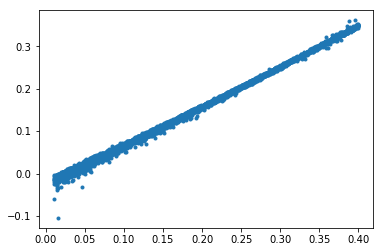



###############################################################################################


                            OLS Regression Results                            
Dep. Variable:          res_tripl_200   R-squared:                       0.996
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                 1.152e+06
Date:                Sun, 12 Nov 2017   Prob (F-statistic):               0.00
Time:                        22:12:48   Log-Likelihood:                 18051.
No. Observations:                5000   AIC:                        -3.610e+04
Df Residuals:                    4998   BIC:                        -3.608e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

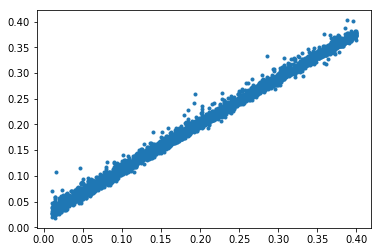



###############################################################################################


                            OLS Regression Results                            
Dep. Variable:          res_multi_200   R-squared:                       0.996
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                 1.183e+06
Date:                Sun, 12 Nov 2017   Prob (F-statistic):               0.00
Time:                        22:12:48   Log-Likelihood:                 17288.
No. Observations:                5000   AIC:                        -3.457e+04
Df Residuals:                    4998   BIC:                        -3.456e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

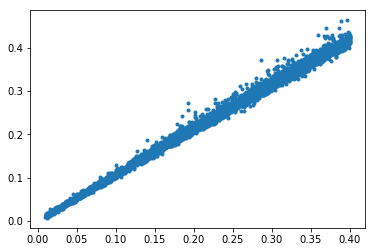

In [5]:
data = pandas.DataFrame({'ff_200' : ff_200, 'res_dixon_200' : res_dixon_200})
mod = smf.ols(formula='res_dixon_200 ~ ff_200', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_200, res_dixon_200, '.')
plt.show()

print('\n')
print('###############################################################################################')
print('\n')

data = pandas.DataFrame({'ff_200' : ff_200, 'res_tripl_200' : res_tripl_200})
mod = smf.ols(formula='res_tripl_200 ~ ff_200', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_200, res_tripl_200, '.')
plt.show()

print('\n')
print('###############################################################################################')
print('\n')

data = pandas.DataFrame({'ff_200' : ff_200, 'res_multi_200' : res_multi_200})
mod = smf.ols(formula='res_multi_200 ~ ff_200', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_200, res_multi_200, '.')
plt.show()

In [6]:
## -------------------------------------> SNR = 100 <------------------------------------- ##
snr_100 = 100

ff_100, res_dixon_100, res_tripl_100, res_multi_100 = zona(snr_100)

print('DIXON 0.04: %.f' % accu(ff_100, res_dixon_100, 0.04))
print('DIXON 0.06: %.f' % accu(ff_100, res_dixon_100, 0.06))
print('DIXON 0.08: %.f' % accu(ff_100, res_dixon_100, 0.08))
print('DIXON 0.10: %.f' % accu(ff_100, res_dixon_100, 0.10))
print('DIXON 0.45: %.f' % accu(ff_100, res_dixon_100, 0.45))
print('DIXON 0.50: %.f' % accu(ff_100, res_dixon_100, 0.50))
print('DIXON 0.55: %.f' % accu(ff_100, res_dixon_100, 0.55))
print('')
print('tripl 0.04: %.f' % accu(ff_100, res_tripl_100, 0.04))
print('tripl 0.06: %.f' % accu(ff_100, res_tripl_100, 0.06))
print('tripl 0.08: %.f' % accu(ff_100, res_tripl_100, 0.08))
print('tripl 0.10: %.f' % accu(ff_100, res_tripl_100, 0.10))
print('tripl 0.45: %.f' % accu(ff_100, res_tripl_100, 0.45))
print('tripl 0.50: %.f' % accu(ff_100, res_tripl_100, 0.50))
print('tripl 0.55: %.f' % accu(ff_100, res_tripl_100, 0.55))
print('')
print('multi 0.04: %.f' % accu(ff_100, res_multi_100, 0.04))
print('multi 0.06: %.f' % accu(ff_100, res_multi_100, 0.06))
print('multi 0.08: %.f' % accu(ff_100, res_multi_100, 0.08))
print('multi 0.10: %.f' % accu(ff_100, res_multi_100, 0.10))
print('multi 0.45: %.f' % accu(ff_100, res_multi_100, 0.45))
print('multi 0.50: %.f' % accu(ff_100, res_multi_100, 0.50))
print('multi 0.55: %.f' % accu(ff_100, res_multi_100, 0.55))

DIXON 0.04: 1
DIXON 0.06: 1
DIXON 0.08: 1
DIXON 0.10: 1
DIXON 0.45: 1
DIXON 0.50: 1
DIXON 0.55: 1

tripl 0.04: 1
tripl 0.06: 1
tripl 0.08: 1
tripl 0.10: 1
tripl 0.45: 1
tripl 0.50: 1
tripl 0.55: 1

multi 0.04: 1
multi 0.06: 1
multi 0.08: 1
multi 0.10: 1
multi 0.45: 1
multi 0.50: 1
multi 0.55: 1


                            OLS Regression Results                            
Dep. Variable:          res_dixon_100   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                 1.849e+06
Date:                Sun, 12 Nov 2017   Prob (F-statistic):               0.00
Time:                        22:14:11   Log-Likelihood:                 18907.
No. Observations:                5000   AIC:                        -3.781e+04
Df Residuals:                    4998   BIC:                        -3.780e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0271      0.000   -169.269      0.0

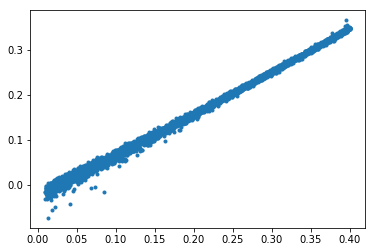



###############################################################################################


                            OLS Regression Results                            
Dep. Variable:          res_tripl_100   R-squared:                       0.994
Model:                            OLS   Adj. R-squared:                  0.994
Method:                 Least Squares   F-statistic:                 8.083e+05
Date:                Sun, 12 Nov 2017   Prob (F-statistic):               0.00
Time:                        22:14:11   Log-Likelihood:                 17110.
No. Observations:                5000   AIC:                        -3.422e+04
Df Residuals:                    4998   BIC:                        -3.420e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

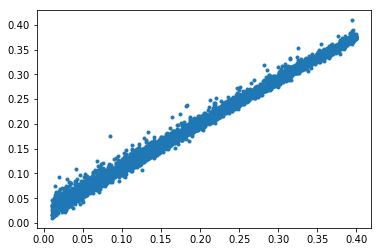



###############################################################################################


                            OLS Regression Results                            
Dep. Variable:          res_multi_100   R-squared:                       0.996
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                 1.220e+06
Date:                Sun, 12 Nov 2017   Prob (F-statistic):               0.00
Time:                        22:14:11   Log-Likelihood:                 17312.
No. Observations:                5000   AIC:                        -3.462e+04
Df Residuals:                    4998   BIC:                        -3.461e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

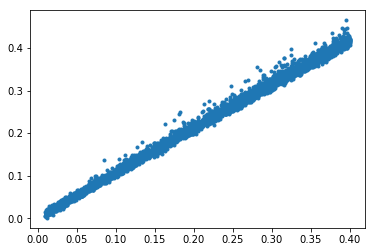

In [7]:
data = pandas.DataFrame({'ff_100' : ff_100, 'res_dixon_100' : res_dixon_100})
mod = smf.ols(formula='res_dixon_100 ~ ff_100', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_100, res_dixon_100, '.')
plt.show()

print('\n')
print('###############################################################################################')
print('\n')

data = pandas.DataFrame({'ff_100' : ff_100, 'res_tripl_100' : res_tripl_100})
mod = smf.ols(formula='res_tripl_100 ~ ff_100', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_100, res_tripl_100, '.')
plt.show()

print('\n')
print('###############################################################################################')
print('\n')

data = pandas.DataFrame({'ff_100' : ff_100, 'res_multi_100' : res_multi_100})
mod = smf.ols(formula='res_multi_100 ~ ff_100', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_100, res_multi_100, '.')
plt.show()

In [8]:
## -------------------------------------> SNR = 50 <------------------------------------- ##
snr_50 = 50

ff_50, res_dixon_50, res_tripl_50, res_multi_50 = zona(snr_50)

print('DIXON 0.04: %.f' % accu(ff_50, res_dixon_50, 0.04))
print('DIXON 0.06: %.f' % accu(ff_50, res_dixon_50, 0.06))
print('DIXON 0.08: %.f' % accu(ff_50, res_dixon_50, 0.08))
print('DIXON 0.10: %.f' % accu(ff_50, res_dixon_50, 0.10))
print('DIXON 0.45: %.f' % accu(ff_50, res_dixon_50, 0.45))
print('DIXON 0.50: %.f' % accu(ff_50, res_dixon_50, 0.50))
print('DIXON 0.55: %.f' % accu(ff_50, res_dixon_50, 0.55))
print('')
print('tripl 0.04: %.f' % accu(ff_50, res_tripl_50, 0.04))
print('tripl 0.06: %.f' % accu(ff_50, res_tripl_50, 0.06))
print('tripl 0.08: %.f' % accu(ff_50, res_tripl_50, 0.08))
print('tripl 0.10: %.f' % accu(ff_50, res_tripl_50, 0.10))
print('tripl 0.45: %.f' % accu(ff_50, res_tripl_50, 0.45))
print('tripl 0.50: %.f' % accu(ff_50, res_tripl_50, 0.50))
print('tripl 0.55: %.f' % accu(ff_50, res_tripl_50, 0.55))
print('')
print('multi 0.04: %.f' % accu(ff_50, res_multi_50, 0.04))
print('multi 0.06: %.f' % accu(ff_50, res_multi_50, 0.06))
print('multi 0.08: %.f' % accu(ff_50, res_multi_50, 0.08))
print('multi 0.10: %.f' % accu(ff_50, res_multi_50, 0.10))
print('multi 0.45: %.f' % accu(ff_50, res_multi_50, 0.45))
print('multi 0.50: %.f' % accu(ff_50, res_multi_50, 0.50))
print('multi 0.55: %.f' % accu(ff_50, res_multi_50, 0.55))

DIXON 0.04: 1
DIXON 0.06: 1
DIXON 0.08: 1
DIXON 0.10: 1
DIXON 0.45: 1
DIXON 0.50: 1
DIXON 0.55: 1

tripl 0.04: 1
tripl 0.06: 1
tripl 0.08: 1
tripl 0.10: 1
tripl 0.45: 1
tripl 0.50: 1
tripl 0.55: 1

multi 0.04: 1
multi 0.06: 1
multi 0.08: 1
multi 0.10: 1
multi 0.45: 1
multi 0.50: 1
multi 0.55: 1


                            OLS Regression Results                            
Dep. Variable:           res_dixon_50   R-squared:                       0.994
Model:                            OLS   Adj. R-squared:                  0.994
Method:                 Least Squares   F-statistic:                 7.947e+05
Date:                Sun, 12 Nov 2017   Prob (F-statistic):               0.00
Time:                        22:15:36   Log-Likelihood:                 16878.
No. Observations:                5000   AIC:                        -3.375e+04
Df Residuals:                    4998   BIC:                        -3.374e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0275      0.000   -113.003      0.0

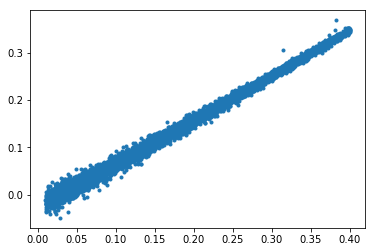



###############################################################################################


                            OLS Regression Results                            
Dep. Variable:           res_tripl_50   R-squared:                       0.985
Model:                            OLS   Adj. R-squared:                  0.985
Method:                 Least Squares   F-statistic:                 3.298e+05
Date:                Sun, 12 Nov 2017   Prob (F-statistic):               0.00
Time:                        22:15:36   Log-Likelihood:                 14939.
No. Observations:                5000   AIC:                        -2.987e+04
Df Residuals:                    4998   BIC:                        -2.986e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

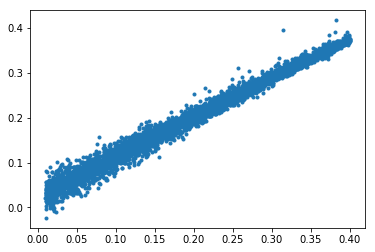



###############################################################################################


                            OLS Regression Results                            
Dep. Variable:           res_multi_50   R-squared:                       0.994
Model:                            OLS   Adj. R-squared:                  0.994
Method:                 Least Squares   F-statistic:                 7.798e+05
Date:                Sun, 12 Nov 2017   Prob (F-statistic):               0.00
Time:                        22:15:36   Log-Likelihood:                 16274.
No. Observations:                5000   AIC:                        -3.254e+04
Df Residuals:                    4998   BIC:                        -3.253e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

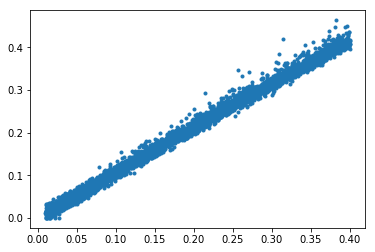

In [9]:
data = pandas.DataFrame({'ff_50' : ff_50, 'res_dixon_50' : res_dixon_50})
mod = smf.ols(formula='res_dixon_50 ~ ff_50', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_50, res_dixon_50, '.')
plt.show()

print('\n')
print('###############################################################################################')
print('\n')

data = pandas.DataFrame({'ff_50' : ff_50, 'res_tripl_50' : res_tripl_50})
mod = smf.ols(formula='res_tripl_50 ~ ff_50', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_50, res_tripl_50, '.')
plt.show()

print('\n')
print('###############################################################################################')
print('\n')

data = pandas.DataFrame({'ff_50' : ff_50, 'res_multi_50' : res_multi_50})
mod = smf.ols(formula='res_multi_50 ~ ff_50', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_50, res_multi_50, '.')
plt.show()

In [10]:
## -------------------------------------> SNR = 25 <------------------------------------- ##
snr_25 = 25

ff_25, res_dixon_25, res_tripl_25, res_multi_25 = zona(snr_25)

print('DIXON 0.04: %.f' % accu(ff_25, res_dixon_25, 0.04))
print('DIXON 0.06: %.f' % accu(ff_25, res_dixon_25, 0.06))
print('DIXON 0.08: %.f' % accu(ff_25, res_dixon_25, 0.08))
print('DIXON 0.10: %.f' % accu(ff_25, res_dixon_25, 0.10))
print('DIXON 0.45: %.f' % accu(ff_25, res_dixon_25, 0.45))
print('DIXON 0.50: %.f' % accu(ff_25, res_dixon_25, 0.50))
print('DIXON 0.55: %.f' % accu(ff_25, res_dixon_25, 0.55))
print('')
print('tripl 0.04: %.f' % accu(ff_25, res_tripl_25, 0.04))
print('tripl 0.06: %.f' % accu(ff_25, res_tripl_25, 0.06))
print('tripl 0.08: %.f' % accu(ff_25, res_tripl_25, 0.08))
print('tripl 0.10: %.f' % accu(ff_25, res_tripl_25, 0.10))
print('tripl 0.45: %.f' % accu(ff_25, res_tripl_25, 0.45))
print('tripl 0.50: %.f' % accu(ff_25, res_tripl_25, 0.50))
print('tripl 0.55: %.f' % accu(ff_25, res_tripl_25, 0.55))
print('')
print('multi 0.04: %.f' % accu(ff_25, res_multi_25, 0.04))
print('multi 0.06: %.f' % accu(ff_25, res_multi_25, 0.06))
print('multi 0.08: %.f' % accu(ff_25, res_multi_25, 0.08))
print('multi 0.10: %.f' % accu(ff_25, res_multi_25, 0.10))
print('multi 0.45: %.f' % accu(ff_25, res_multi_25, 0.45))
print('multi 0.50: %.f' % accu(ff_25, res_multi_25, 0.50))
print('multi 0.55: %.f' % accu(ff_25, res_multi_25, 0.55))

DIXON 0.04: 1
DIXON 0.06: 1
DIXON 0.08: 1
DIXON 0.10: 1
DIXON 0.45: 1
DIXON 0.50: 1
DIXON 0.55: 1

tripl 0.04: 1
tripl 0.06: 1
tripl 0.08: 1
tripl 0.10: 1
tripl 0.45: 1
tripl 0.50: 1
tripl 0.55: 1

multi 0.04: 1
multi 0.06: 1
multi 0.08: 1
multi 0.10: 1
multi 0.45: 1
multi 0.50: 1
multi 0.55: 1


                            OLS Regression Results                            
Dep. Variable:           res_dixon_25   R-squared:                       0.980
Model:                            OLS   Adj. R-squared:                  0.980
Method:                 Least Squares   F-statistic:                 2.436e+05
Date:                Sun, 12 Nov 2017   Prob (F-statistic):               0.00
Time:                        22:17:05   Log-Likelihood:                 13946.
No. Observations:                5000   AIC:                        -2.789e+04
Df Residuals:                    4998   BIC:                        -2.788e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0278      0.000    -62.583      0.0

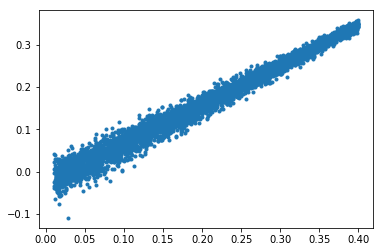



###############################################################################################


                            OLS Regression Results                            
Dep. Variable:           res_tripl_25   R-squared:                       0.955
Model:                            OLS   Adj. R-squared:                  0.955
Method:                 Least Squares   F-statistic:                 1.068e+05
Date:                Sun, 12 Nov 2017   Prob (F-statistic):               0.00
Time:                        22:17:05   Log-Likelihood:                 12131.
No. Observations:                5000   AIC:                        -2.426e+04
Df Residuals:                    4998   BIC:                        -2.425e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

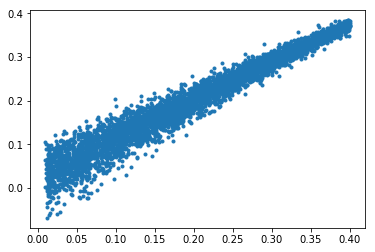



###############################################################################################


                            OLS Regression Results                            
Dep. Variable:           res_multi_25   R-squared:                       0.988
Model:                            OLS   Adj. R-squared:                  0.988
Method:                 Least Squares   F-statistic:                 4.049e+05
Date:                Sun, 12 Nov 2017   Prob (F-statistic):               0.00
Time:                        22:17:05   Log-Likelihood:                 14658.
No. Observations:                5000   AIC:                        -2.931e+04
Df Residuals:                    4998   BIC:                        -2.930e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

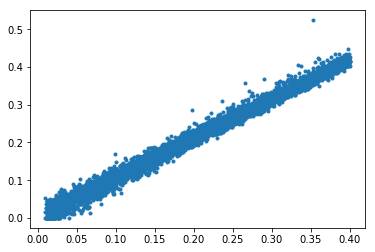

In [11]:
data = pandas.DataFrame({'ff_25' : ff_25, 'res_dixon_25' : res_dixon_25})
mod = smf.ols(formula='res_dixon_25 ~ ff_25', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_25, res_dixon_25, '.')
plt.show()

print('\n')
print('###############################################################################################')
print('\n')

data = pandas.DataFrame({'ff_25' : ff_25, 'res_tripl_25' : res_tripl_25})
mod = smf.ols(formula='res_tripl_25 ~ ff_25', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_25, res_tripl_25, '.')
plt.show()

print('\n')
print('###############################################################################################')
print('\n')

data = pandas.DataFrame({'ff_25' : ff_25, 'res_multi_25' : res_multi_25})
mod = smf.ols(formula='res_multi_25 ~ ff_25', data=data)
res = mod.fit()
print(res.summary())
plt.plot(ff_25, res_multi_25, '.')
plt.show()